# Упражнения по регуляризации и методу градиентного спуска

## Подготовка

In [1]:
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('sklearnex не установлен, работает обычный scikit-learn')

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, learning_curve, GridSearchCV, KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, ElasticNet, LassoCV, SGDRegressor, lasso_path
from sklearn.metrics import mean_squared_error, mean_absolute_error

%matplotlib inline
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 40)

# в папке курса данные лежат в data/, у меня - в общей папке "Seturi de date"
data_dir = 'data' if os.path.isdir('data') else os.path.join('..', 'Seturi de date')


def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


def fmt_table(df, formats):
    """Форматирует столбцы таблицы для вывода (замена df.style.format, которому нужен jinja2)."""
    out = df.astype(object).copy()
    for col, f in formats.items():
        if col in out:
            out[col] = [f.format(v) if pd.notna(v) else '-' for v in df[col]]
    return out

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1: Генерация нелинейных данных с гетероскедастичным шумом

В реальных задачах шум в данных часто зависит от значения входных признаков (гетероскедастичность).

* Сгенерируйте 250 равномерно распределенных точек $x$ на отрезке $[0, 5]$.
* Вычислите истинное значение целевой переменной по формуле: $y_{\text{true}} = 2.5 \cdot \sin(1.5 x) + 0.3 x^2 - 1.5$.

* Добавьте гауссов шум, дисперсия которого растет линейно с ростом $x$: $\sigma(x) = 0.15 \cdot (1 + 0.8x)$.

* Разделите данные на обучающую (70%) и тестовую (30%) выборки с фиксированным `random_state=42`.
* Постройте график тренировочных, тестовых точек и истинной функции.

In [2]:
rng = np.random.default_rng(42)


def f_true(x):
    return 2.5 * np.sin(1.5 * x) + 0.3 * x ** 2 - 1.5


def noise_sigma(x):
    return 0.15 * (1 + 0.8 * x)


x = np.linspace(0, 5, 250)
y = f_true(x) + rng.normal(0, noise_sigma(x))
X = x.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
x_grid = np.linspace(0, 5, 1000).reshape(-1, 1)

# "неустранимая" ошибка: RMSE самой истинной функции на этих данных
noise_rmse_train = rmse(y_train, f_true(X_train.ravel()))
noise_rmse_test = rmse(y_test, f_true(X_test.ravel()))
print(f'train: {len(X_train)} точек, test: {len(X_test)} точек')
print(f'sigma шума: {noise_sigma(0):.2f} при x = 0, {noise_sigma(5):.2f} при x = 5')
print(f'RMSE истинной функции (уровень шума): train {noise_rmse_train:.3f}, test {noise_rmse_test:.3f}')

train: 175 точек, test: 75 точек
sigma шума: 0.15 при x = 0, 0.75 при x = 5
RMSE истинной функции (уровень шума): train 0.506, test 0.490


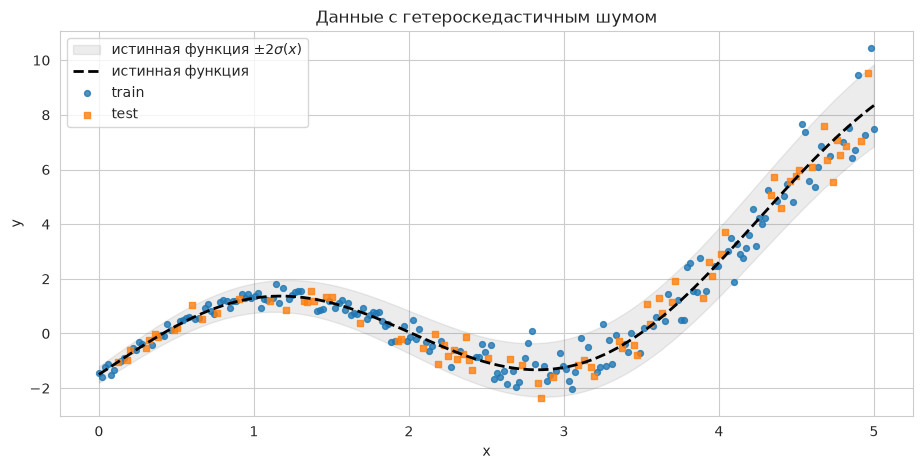

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
g = x_grid.ravel()
ax.fill_between(g, f_true(g) - 2 * noise_sigma(g), f_true(g) + 2 * noise_sigma(g),
                color='grey', alpha=0.15, label=r'истинная функция $\pm 2\sigma(x)$')
ax.plot(g, f_true(g), 'k--', lw=2, label='истинная функция')
ax.scatter(X_train, y_train, s=18, alpha=0.8, label='train')
ax.scatter(X_test, y_test, s=22, marker='s', alpha=0.8, label='test')
ax.set(xlabel='x', ylabel='y', title='Данные с гетероскедастичным шумом')
ax.legend()
plt.show()

**Ответ.**

250 точек, в train 175, в test 75. Шум растет вместе с `x`: sigma = 0.15 при x = 0 и 0.75 при x = 5, в 5 раз больше. На графике это видно: слева точки лежат почти на кривой, справа облако заметно шире (серая полоса - истинная функция плюс-минус 2 sigma).

Сама истинная функция ошибается на этих данных на RMSE 0.51 (train) и 0.49 (test). Это неустранимая ошибка: никакая модель не будет в среднем точнее, поэтому дальше сравниваю ошибки моделей с этим уровнем.

## Вопрос 2: Исследование полиномов высокой степени и феномена Рунге

При слишком высокой степени полинома модель стремится идеально пройти через все точки обучающей выборки, образуя сильные осцилляции на краях интервала.

* Сформируйте полиномиальные признаки 25-й степени (`degree=25`).

* Обучите обычную линейную регрессию (`LinearRegression`) без регуляризации.

* Оцените $RMSE$ на обучающей и тестовой выборках.

Постройте график предсказаний модели на всем отрезке $[0, 5]$. Проанализируйте осцилляции модели на границах интервала.

In [4]:
pf25 = PolynomialFeatures(degree=25)
P_train, P_test = pf25.fit_transform(X_train), pf25.transform(X_test)
lr25 = LinearRegression().fit(P_train, y_train)

print('признаков:', P_train.shape[1], ' максимальное значение x^25:', f'{P_train[:, -1].max():.2e}')
print(f'число обусловленности матрицы признаков: {np.linalg.cond(P_train):.1e}')
print(f'RMSE train: {rmse(y_train, lr25.predict(P_train)):.3f}')
print(f'RMSE test:  {rmse(y_test, lr25.predict(P_test)):.3f}')
print('коэффициенты от', f'{np.abs(lr25.coef_[1:]).min():.1e}', 'до', f'{np.abs(lr25.coef_[1:]).max():.1e}')

признаков: 26  максимальное значение x^25: 2.98e+17
число обусловленности матрицы признаков: 4.9e+24
RMSE train: 0.978
RMSE test:  0.901
коэффициенты от 4.0e-22 до 6.6e-12


In [5]:
# Что делать с численной проблемой. Просто стандартизовать x^k мало: на [0, 5] все степени растут монотонно
# и почти коллинеарны. Помогает сначала перевести x в [-1, 1]: четные и нечетные степени становятся разными.
def poly_model(degree, model):
    return make_pipeline(MinMaxScaler(feature_range=(-1, 1)), PolynomialFeatures(degree, include_bias=False),
                         StandardScaler(), model)


def cond_of(pipe, X):
    A = pipe.fit_transform(X)
    return np.linalg.cond(np.c_[np.ones(len(A)), A])


print('число обусловленности (с константой), степень 25:')
print(f'  x^k на [0, 5]:                     {np.linalg.cond(P_train):.1e}')
print(f'  x^k на [0, 5] + StandardScaler:     {cond_of(make_pipeline(PolynomialFeatures(25, include_bias=False), StandardScaler()), X_train):.1e}')
print(f'  x -> [-1, 1], x^k, StandardScaler:  {cond_of(poly_model(25, "passthrough")[:-1], X_train):.1e}')

lr25s = poly_model(25, LinearRegression()).fit(X_train, y_train)
print(f'\nстепень 25 в нормальном базисе: RMSE train {rmse(y_train, lr25s.predict(X_train)):.3f}, '
      f'test {rmse(y_test, lr25s.predict(X_test)):.3f}, максимальный |коэффициент| {np.abs(lr25s[-1].coef_).max():.2e}')

число обусловленности (с константой), степень 25:
  x^k на [0, 5]:                     4.9e+24
  x^k на [0, 5] + StandardScaler:     6.6e+16
  x -> [-1, 1], x^k, StandardScaler:  8.1e+08

степень 25 в нормальном базисе: RMSE train 0.476, test 0.461, максимальный |коэффициент| 2.84e+05


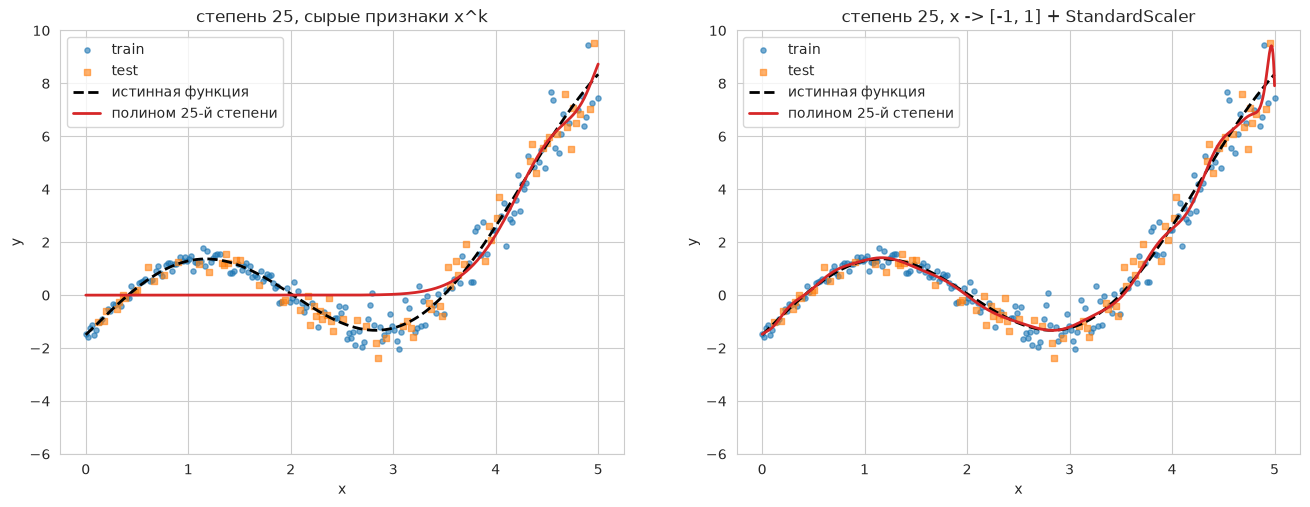

степень 25, сырые признаки x^k: макс. отклонение от истинной функции на краях 1.50 (при x = 0.00), в середине 1.37 (при x = 1.17)
степень 25, x -> [-1, 1] + StandardScaler: макс. отклонение от истинной функции на краях 1.21 (при x = 4.96), в середине 0.38 (при x = 4.16)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
g = x_grid.ravel()
preds_q2 = {'степень 25, сырые признаки x^k': lr25.predict(pf25.transform(x_grid)),
            'степень 25, x -> [-1, 1] + StandardScaler': lr25s.predict(x_grid)}
for ax, (title, pred) in zip(axes, preds_q2.items()):
    ax.scatter(X_train, y_train, s=14, alpha=0.6, label='train')
    ax.scatter(X_test, y_test, s=18, marker='s', alpha=0.6, label='test')
    ax.plot(g, f_true(g), 'k--', lw=2, label='истинная функция')
    ax.plot(g, pred, lw=2, color='C3', label='полином 25-й степени')
    ax.set(xlabel='x', ylabel='y', title=title, ylim=(-6, 10))
    ax.legend(loc='upper left')
plt.show()

# где модель дальше всего от истинной функции: края против середины
edges = (g < 0.5) | (g > 4.5)          # по 10% интервала с каждого края
for name, pred in preds_q2.items():
    dev = np.abs(pred - f_true(g))
    print(f'{name}: макс. отклонение от истинной функции на краях {dev[edges].max():.2f} '
          f'(при x = {g[edges][dev[edges].argmax()]:.2f}), в середине {dev[~edges].max():.2f} '
          f'(при x = {g[~edges][dev[~edges].argmax()]:.2f})')

**Ответ.**

**Сырые признаки `x^k`, как в задании.** `x^25` доходит до 3·10^17, число обусловленности матрицы признаков 4.9·10^24. Это больше, чем 1/eps для float64 (около 4.5·10^15), то есть задачу в такой форме точно решить нельзя. Решатель отбрасывает направления с крошечными сингулярными числами, а это как раз младшие степени `x`. Поэтому на левом графике модель равна нулю на всем участке x < 3, где старшие степени еще маленькие. RMSE train 0.98, test 0.90, вдвое хуже уровня шума. Это не переобучение, а численная поломка, и дело не в sklearnex: обычный scikit-learn, по моей отдельной проверке, дает то же самое (RMSE train 1.02).

Просто стандартизовать столбцы `x^k` мало: на [0, 5] все степени монотонно растут и почти коллинеарны, число обусловленности все равно 6.6·10^16. Помогает сначала перевести `x` в [-1, 1] и только потом возводить в степени. Четные и нечетные степени становятся непохожими, и число обусловленности падает до 8·10^8. Дальше полиномы строю так.

**Степень 25 в нормальном базисе.** RMSE train 0.476, то есть ниже уровня шума 0.506: модель подгоняется под часть шума. RMSE test 0.461. Коэффициенты доходят до 2.8·10^5 по модулю: огромные веса с разными знаками почти гасят друг друга. Это типичный признак переобучения.

**Края интервала.** Самое большое отклонение от истинной функции 1.21 при x = 4.96, а внутри интервала не больше 0.38. На графике у правого края кривая сначала идет вдоль данных, а в последней десятой доли интервала делает резкий выброс вверх до 9.5 и обратно. Это эффект Рунге: в середине полином зажат точками с обеих сторон, а на краю только с одной, и старшие степени сильнее всего растут именно на краях, поэтому маленькая ошибка в коэффициенте там усиливается больше всего. Справа еще и шум самый большой (sigma = 0.75), поэтому правый край колеблется сильнее левого. RMSE на test при этом выглядит нормально, потому что тестовых точек у самого края мало. Вне [0, 5], при экстраполяции, полином 25-й степени сразу ушел бы в бесконечность.

## Вопрос 3: Диагностика Bias-Variance с помощью кривых обучения (Learning Curves)

Кривые обучения позволяют определить, принесет ли пользу добавление новых данных или необходима регуляризация.

* Напишите функцию для расчета и построения кривых обучения с помощью `learning_curve` из `sklearn.model_selection`.

* Постройте кривые обучения для неуправляемой линейной регрессии (степень 15) и Ridge-регрессии (степень 15, $\alpha = 1.0$).

* Объясните разрыв (*generalization gap*) между ошибкой на обучении и валидации для обеих моделей.

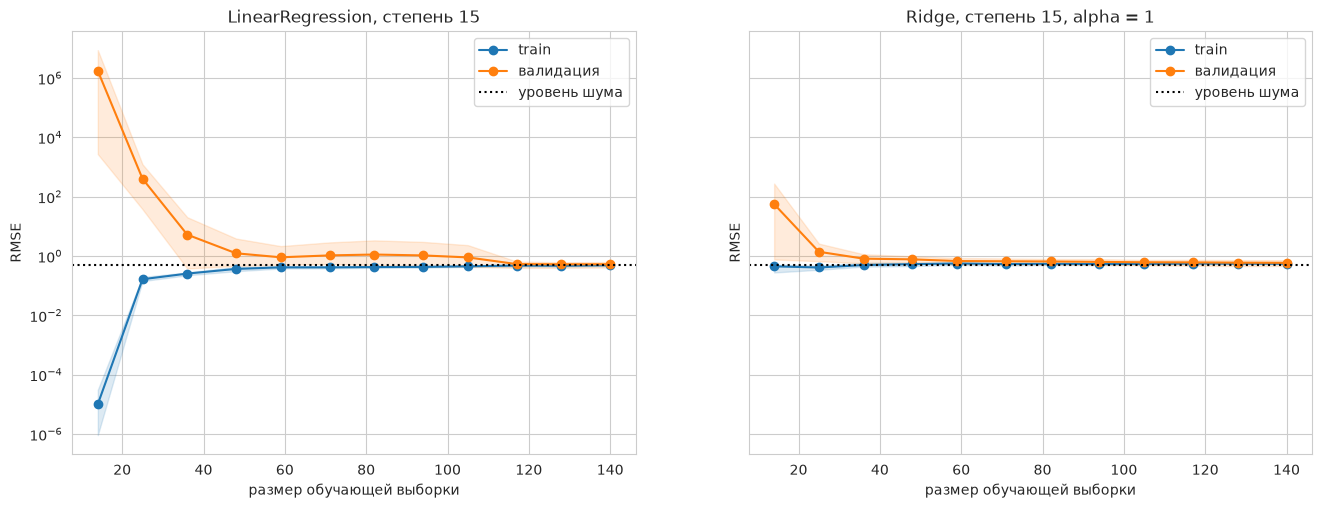

LinearRegression, степень 15                              \
                      RMSE train RMSE валидация       разрыв   
14                         0.000    1737764.651  1737764.651   
25                         0.164        400.648      400.484   
36                         0.255          5.232        4.976   
48                         0.366          1.233        0.866   
59                         0.414          0.902        0.488   
71                         0.414          1.047        0.633   
82                         0.424          1.119        0.695   
94                         0.429          1.044        0.615   
105                        0.449          0.895        0.446   
117                        0.476          0.533        0.057   
128                        0.470          0.525        0.055   
140                        0.487          0.527        0.040   

    Ridge, степень 15, alpha = 1                         
                      RMSE train RMSE валидация  разрыв  
14                         0.447         55.861  55.413  
25                         0.410          1.387   0.977  
36                         0.494          0.812   0.318  
48                         0.531          0.770   0.239  
59                         0.558          0.676   0.118  
71                         0.536          0.664   0.128  
82                         0.547          0.654   0.107  
94                         0.536          0.632   0.097  
105                        0.541          0.615   0.074  
117                        0.557          0.610   0.053  
128                        0.552          0.595   0.044  
140                        0.546          0.588   0.041

In [7]:
def plot_learning_curve(estimator, X, y, title, ax, noise_level=None,
                        train_sizes=np.linspace(0.1, 1.0, 12),
                        cv=KFold(n_splits=5, shuffle=True, random_state=42)):
    """Строит кривые обучения (RMSE на train и на валидации) и возвращает таблицу средних."""
    sizes, train_scores, val_scores = learning_curve(
        estimator, X, y, train_sizes=train_sizes, cv=cv,
        scoring='neg_root_mean_squared_error', n_jobs=-1)
    train_rmse, val_rmse = -train_scores, -val_scores
    for scores, label, color in [(train_rmse, 'train', 'C0'), (val_rmse, 'валидация', 'C1')]:
        ax.plot(sizes, scores.mean(axis=1), 'o-', color=color, label=label)
        # полоса - от худшего до лучшего фолда (на лог-шкале это нагляднее, чем +-std)
        ax.fill_between(sizes, scores.min(axis=1), scores.max(axis=1), color=color, alpha=0.15)
    if noise_level is not None:
        ax.axhline(noise_level, color='k', ls=':', label='уровень шума')
    ax.set(xlabel='размер обучающей выборки', ylabel='RMSE', title=title, yscale='log')
    ax.legend()
    return pd.DataFrame({'RMSE train': train_rmse.mean(axis=1), 'RMSE валидация': val_rmse.mean(axis=1),
                         'разрыв': val_rmse.mean(axis=1) - train_rmse.mean(axis=1)}, index=sizes)


models_lc = {
    'LinearRegression, степень 15': poly_model(15, LinearRegression()),
    'Ridge, степень 15, alpha = 1': poly_model(15, Ridge(alpha=1.0)),
}
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
curves = {}
for ax, (name, model) in zip(axes, models_lc.items()):
    curves[name] = plot_learning_curve(model, X_train, y_train, name, ax, noise_level=noise_rmse_train)
plt.show()

pd.concat(curves, axis=1).round(3)

In [8]:
# alpha = 1 - не единственный вариант: ошибка на кросс-валидации для разных alpha (все 175 точек train)
from sklearn.model_selection import validation_curve

ridge_alphas = np.logspace(-6, 2, 9)
tr_sc, va_sc = validation_curve(poly_model(15, Ridge()),
                                X_train, y_train, param_name='ridge__alpha', param_range=ridge_alphas,
                                cv=KFold(n_splits=5, shuffle=True, random_state=42),
                                scoring='neg_root_mean_squared_error')
pd.DataFrame({'RMSE train': -tr_sc.mean(axis=1), 'RMSE валидация': -va_sc.mean(axis=1)},
             index=pd.Index(ridge_alphas, name='alpha')).round(3).T

alpha,0.000001,0.000010,0.000100,0.001000,0.010000,0.100000,1.000000,10.000000,100.000000
RMSE train,0.493,0.494,0.495,0.496,0.497,0.502,0.546,0.732,1.116
RMSE валидация,0.529,0.527,0.524,0.524,0.526,0.528,0.588,0.764,1.135


In [9]:
# откуда горб на кривой LinearRegression: разберу фолды при 71 и 117 точках обучения
rows = {}
for n_fit in [71, 117]:
    for k, (tr, va) in enumerate(KFold(n_splits=5, shuffle=True, random_state=42).split(X_train)):
        sub = tr[:n_fit]                   # learning_curve берет первые n объектов train-части фолда
        m = poly_model(15, LinearRegression()).fit(X_train[sub], y_train[sub])
        sq_err = (m.predict(X_train[va]) - y_train[va]) ** 2
        xv = X_train[va].ravel()
        edge = (xv < 0.5) | (xv > 4.5)
        rows[(f'{n_fit} точек', f'фолд {k}')] = {'RMSE': np.sqrt(sq_err.mean()), 'x train: от': X_train[sub].min(),
                                                 'x train: до': X_train[sub].max(), 'x валидации: до': xv.max(),
                                                 'доля ошибки на краях': sq_err[edge].sum() / sq_err.sum()}
fmt_table(pd.DataFrame(rows).T, {'RMSE': '{:.2f}', 'x train: от': '{:.2f}', 'x train: до': '{:.2f}',
                                 'x валидации: до': '{:.2f}', 'доля ошибки на краях': '{:.0%}'})

RMSE x train: от x train: до x валидации: до  \
71 точек  фолд 0  0.54        0.00        4.98            4.86   
          фолд 1  0.65        0.00        4.98            4.88   
          фолд 2  2.87        0.04        4.90            5.00   
          фолд 3  0.58        0.00        4.98            4.64   
          фолд 4  0.60        0.00        4.98            4.94   
117 точек фолд 0  0.50        0.00        4.98            4.86   
          фолд 1  0.53        0.00        4.98            4.88   
          фолд 2  0.65        0.04        4.94            5.00   
          фолд 3  0.40        0.00        4.98            4.64   
          фолд 4  0.59        0.00        4.98            4.94   

                 доля ошибки на краях  
71 точек  фолд 0                  30%  
          фолд 1                  45%  
          фолд 2                  98%  
          фолд 3                  29%  
          фолд 4                  74%  
117 точек фолд 0                  19%  
          фолд 1                  25%  
          фолд 2                  62%  
          фолд 3                  12%  
          фолд 4                  72%

**Ответ.**

Обе модели в пайплайне `x -> [-1, 1] -> PolynomialFeatures(15) -> StandardScaler -> модель`, иначе, как видно в вопросе 2, решатель ломается численно (а штраф Ridge зависел бы от единиц признака).

**LinearRegression, степень 15 (16 коэффициентов).** При 14 точках модель проходит через них точно: RMSE train 0, а на валидации 1.7·10^6. Разрыв огромный, это большая дисперсия (переобучение). При 36 точках валидация уже 5.2, при 48 - 1.23. Потом до 105 точек идет горб (0.9-1.1), и только с 117 точек ошибка падает до 0.53. При 140 точках train 0.487, валидация 0.527, разрыв 0.04, обе кривые почти на уровне шума 0.51.

Горб дает один фолд. В таблице выше при 71 точке у фолда 2 обучающая часть кончается на x = 4.90, а в валидации есть точки до 5.00. Модель экстраполирует (RMSE 2.87), и 98% квадратичной ошибки этого фолда приходится на края. При 117 точках обучающая часть того же фолда доходит до 4.94, его RMSE падает до 0.65, и горб исчезает. Это та же проблема краев, что и в вопросе 2.

**Ridge, степень 15, alpha = 1.** Дисперсия намного меньше: при 14 точках валидация 56 вместо 1.7·10^6, при 36 точках 0.81 вместо 5.2, горба нет, а с 59 точек разрыв train-валидация уже около 0.1 и плавно уменьшается до 0.04. Цена за это - небольшое смещение: при 140 точках train 0.546 выше уровня шума 0.506, а валидация 0.588 хуже, чем у LinearRegression (0.527). По таблице для разных alpha лучшая валидация при alpha = 1e-4...1e-3 (0.524). alpha = 1 - уже слегка сильный штраф, при alpha = 10 валидация 0.764, при 100 - 1.135 (явное недообучение).

**Как читать разрыв.** Большой разрыв между train и валидацией значит высокую дисперсию: помогают регуляризация или больше данных. Здесь при малых выборках Ridge выигрывает у LinearRegression на порядки, а при 140 точках данных уже хватает, и регуляризация почти не нужна. Маленький разрыв при высокой ошибке на обеих кривых значит высокое смещение: нужна более гибкая модель или более слабый штраф.

## Вопрос 4: Подготовка продвинутых признаков и обработка Ames Housing

Перейдем к реальному набору данных о продажах недвижимости `Ames_Housing_Sales.csv`.

* Загрузите датасет, выполните One-Hot Encoding категориальных признаков.

* Проверьте признаки на асимметрию (`skew > 0.75`) и примените преобразование `np.log1p`.

* Создайте парные взаимодействия признаков только для ключевых числовых переменных (`LotArea`, `GrLivArea`, `TotalBsmtSF`), используя `PolynomialFeatures(interaction_only=True)`.

Разделите данные на обучающую и тестовую выборки (70/30).

In [10]:
# "None" в этих данных - это категория "нет" (нет аллеи, бассейна...), а не пропуск (см. лабу 3)
ames = pd.read_csv(os.path.join(data_dir, 'Ames_Housing_Sales.csv'), keep_default_na=False)
print('форма:', ames.shape, ' пропусков:', ames.isna().sum().sum())

# MSSubClass - это код типа здания (20, 60, 120...), то есть категория, а не число
ames['MSSubClass'] = ames['MSSubClass'].astype(str)

target = 'SalePrice'
num_cols = ames.select_dtypes(include='number').columns.drop(target)
cat_cols = ames.select_dtypes(exclude='number').columns
print(f'числовых признаков: {len(num_cols)}, категориальных: {len(cat_cols)}')
print(f'асимметрия SalePrice: {ames[target].skew():.2f}')

# One-Hot: n - 1 столбцов на признак, чтобы не было dummy trap
ames_ohe = pd.get_dummies(ames, columns=list(cat_cols), drop_first=True, dtype=float)
print('после One-Hot:', ames_ohe.shape)

форма: (1379, 80)  пропусков: 0
числовых признаков: 35, категориальных: 44
асимметрия SalePrice: 1.94
после One-Hot: (1379, 265)


In [11]:
X_ames = ames_ohe.drop(columns=target)
y_ames = np.log1p(ames_ohe[target])   # цель тоже скошена (skew 1.9) - работаем с log цены

X_train_ames, X_test_ames, y_train_ames, y_test_ames = train_test_split(
    X_ames, y_ames, test_size=0.3, random_state=42)

# какие признаки логарифмировать, решаю по train, чтобы test не влиял на обучение
skew = X_train_ames[num_cols].skew()
skewed_cols = skew[skew.abs() > 0.75].sort_values(ascending=False)
print(f'skew > 0.75 у {len(skewed_cols)} из {len(num_cols)} числовых признаков:')
print(skewed_cols.round(2).to_string())

X_train_ames = X_train_ames.copy()
X_test_ames = X_test_ames.copy()
X_train_ames[skewed_cols.index] = np.log1p(X_train_ames[skewed_cols.index])
X_test_ames[skewed_cols.index] = np.log1p(X_test_ames[skewed_cols.index])

skew > 0.75 у 22 из 35 числовых признаков:
MiscVal          26.92
PoolArea         15.78
LotArea          11.50
LowQualFinSF     11.21
3SsnPorch        10.15
KitchenAbvGr      5.50
ScreenPorch       4.60
BsmtFinSF2        4.47
BsmtHalfBath      3.88
EnclosedPorch     3.22
LotFrontage       3.14
MasVnrArea        2.49
OpenPorchSF       2.30
BsmtFinSF1        2.01
TotalBsmtSF       1.98
1stFlrSF          1.54
GrLivArea         1.46
WoodDeckSF        1.33
OverallCond       0.99
BsmtUnfSF         0.90
GarageArea        0.84
2ndFlrSF          0.77


In [12]:
# парные взаимодействия только для трех ключевых площадей
inter_cols = ['LotArea', 'GrLivArea', 'TotalBsmtSF']
pf_int = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False).fit(X_train_ames[inter_cols])
names = pf_int.get_feature_names_out(inter_cols)
new_names = [n for n in names if ' ' in n]            # только произведения, сами признаки уже есть
for part in (X_train_ames, X_test_ames):
    inter = pd.DataFrame(pf_int.transform(part[inter_cols]), columns=names, index=part.index)[new_names]
    part[[n.replace(' ', '*') for n in new_names]] = inter
print('новые признаки:', [n.replace(' ', '*') for n in new_names])

# One-Hot столбцы, которые в train все нулевые (категория есть только в test), модели ничего не дают
const = X_train_ames.columns[X_train_ames.nunique() <= 1]
X_train_ames = X_train_ames.drop(columns=const)
X_test_ames = X_test_ames.drop(columns=const)
print(f'удалено постоянных в train столбцов: {len(const)}')
print('train:', X_train_ames.shape, ' test:', X_test_ames.shape)

новые признаки: ['LotArea*GrLivArea', 'LotArea*TotalBsmtSF', 'GrLivArea*TotalBsmtSF']
удалено постоянных в train столбцов: 10
train: (965, 257)  test: (414, 257)


**Ответ.**

- Читаю с `keep_default_na=False`: строка `"None"` в этих данных значит «нет» (нет бассейна, забора...), а pandas по умолчанию сделал бы из нее пропуск (ловушка из лабы 3). Получается 1379 x 80, пропусков нет.
- `MSSubClass` - код типа здания (20, 60, 120...), то есть категория, поэтому перевел его в строки. Стало 35 числовых признаков и 44 категориальных.
- One-Hot с `drop_first=True` (n - 1 столбцов на признак, чтобы не было dummy trap): 265 столбцов.
- **Цель.** У `SalePrice` асимметрия 1.94, поэтому дальше предсказываю `log1p(SalePrice)`. RMSE в log-шкале - это примерно относительная ошибка (0.1 значит около 10%), а когда нужно, пересчитываю в доллары через `expm1`. Еще одна причина: сетки alpha из вопросов 5-6 (от 1e-4 до 10) имеют смысл для цели порядка единицы. Для цены в долларах (порядка 10^5) даже alpha = 10 был бы ничтожным штрафом.
- Разбиение 70/30 (`random_state=42`) сделал **до** выбора признаков для логарифма: асимметрию считаю только по train, чтобы test ни на что не влиял. Само преобразование `log1p` ничего не обучает, поэтому к train и test применяется одинаково.
- У 22 из 35 числовых признаков |skew| > 0.75, сильнее всего у `MiscVal` (26.9), `PoolArea` (15.8), `LotArea` (11.5). Все три ключевые площади (`LotArea`, `GrLivArea`, `TotalBsmtSF`) тоже скошены, их логарифмирую.
- Взаимодействия `PolynomialFeatures(interaction_only=True)` строю после логарифма: `LotArea*GrLivArea`, `LotArea*TotalBsmtSF`, `GrLivArea*TotalBsmtSF`.
- 10 One-Hot столбцов в train целиком нулевые (категория встречается только в test). Модель ничего по ним не выучит, поэтому их удалил.

Итого train 965 x 257, test 414 x 257.

## Вопрос 5: Двумерный сетчатый поиск гиперпараметров ElasticNet с GridSearchCV

Регрессия `ElasticNet` комбинирует $L_1$ и $L_2$ штрафы через два ключевых гиперпараметра: $\alpha$ (сила регуляризации) и `l1_ratio` (доля $L_1$-штрафа).

* Настройте сетку параметров: `alpha`: `[1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0]`, `l1_ratio`: `[0.1, 0.3, 0.5, 0.7, 0.9]`.

* Запустите `GridSearchCV` с 5-кратной кросс-валидацией (`cv=5`) и метрикой `neg_root_mean_squared_error`.

* Визуализируйте результаты сетчатого поиска в виде тепловой карты (`sns.heatmap`).

* Выведите оптимальные параметры и оцените итоговое $RMSE$ на тестовой выборке.

In [13]:
param_grid = {'elasticnet__alpha': [1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0],
              'elasticnet__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]}
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)

# масштабирование внутри пайплайна: на каждом фолде scaler учится только на его train-части
enet_pipe = make_pipeline(StandardScaler(), ElasticNet(max_iter=50_000))
grid = GridSearchCV(enet_pipe, param_grid, cv=cv5, scoring='neg_root_mean_squared_error', n_jobs=-1)
t0 = time.time()
grid.fit(X_train_ames, y_train_ames)
print(f'сетчатый поиск: {len(grid.cv_results_["params"]) * cv5.n_splits} обучений за {time.time() - t0:.1f} с')
print('лучшие параметры:', grid.best_params_)
print(f'RMSE кросс-валидации (log цены): {-grid.best_score_:.4f}')

сетчатый поиск: 150 обучений за 2.0 с
лучшие параметры: {'elasticnet__alpha': 0.01, 'elasticnet__l1_ratio': 0.3}
RMSE кросс-валидации (log цены): 0.1162


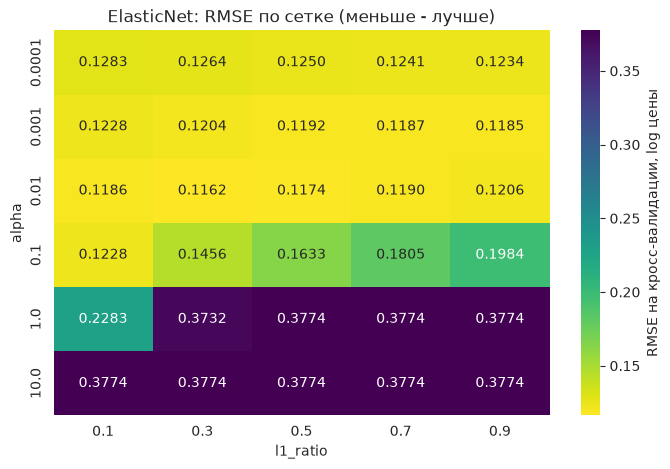

In [14]:
cv_res = pd.DataFrame(grid.cv_results_)
heat = cv_res.pivot(index='param_elasticnet__alpha', columns='param_elasticnet__l1_ratio',
                    values='mean_test_score').mul(-1)
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt='.4f', cmap='viridis_r', ax=ax,
            cbar_kws={'label': 'RMSE на кросс-валидации, log цены'})
ax.set(xlabel='l1_ratio', ylabel='alpha', title='ElasticNet: RMSE по сетке (меньше - лучше)')
plt.show()

In [15]:
best_enet = grid.best_estimator_
pred_log = best_enet.predict(X_test_ames)
enet_coef = best_enet[-1].coef_
print(f'RMSE test (log цены): {rmse(y_test_ames, pred_log):.4f}')
print(f'RMSE test в долларах: {rmse(np.expm1(y_test_ames), np.expm1(pred_log)):,.0f}')
print(f'MAE test в долларах:  {mean_absolute_error(np.expm1(y_test_ames), np.expm1(pred_log)):,.0f}')
print(f'ненулевых коэффициентов: {(enet_coef != 0).sum()} из {len(enet_coef)}')

RMSE test (log цены): 0.1790
RMSE test в долларах: 33,898
MAE test в долларах:  17,068
ненулевых коэффициентов: 108 из 257


In [16]:
# для сравнения: та же схема без регуляризации, и вклад самых плохих домов test
from sklearn.model_selection import cross_val_score

ols_pipe = make_pipeline(StandardScaler(), LinearRegression())
cmp_rows = {}
for name, model in [('OLS без регуляризации', ols_pipe), ('ElasticNet (лучший)', best_enet)]:
    cv_scores = -cross_val_score(model, X_train_ames, y_train_ames, cv=cv5, scoring='neg_root_mean_squared_error')
    model.fit(X_train_ames, y_train_ames)
    err = y_test_ames - model.predict(X_test_ames)
    worst3 = err.abs().sort_values(ascending=False).index[:3]
    cmp_rows[name] = {'RMSE CV (среднее)': cv_scores.mean(), 'RMSE CV по фолдам': np.round(cv_scores, 3),
                      'RMSE test': np.sqrt((err ** 2).mean()),
                      'RMSE test без 3 худших домов': np.sqrt((err.drop(worst3) ** 2).mean()),
                      'доля 3 худших в сумме квадратов': (err[worst3] ** 2).sum() / (err ** 2).sum(),
                      '3 худших дома': list(worst3)}
pd.DataFrame(cmp_rows).T

,RMSE CV (среднее),RMSE CV по фолдам,RMSE test,RMSE test без 3 худших домов,доля 3 худших в сумме квадратов,3 худших дома
OLS без регуляризации,0.176327,"[0.218, 0.291, 0.121, 0.145, 0.107]",0.168748,0.138822,0.328144,"[1105, 493, 1345]"
ElasticNet (лучший),0.116243,"[0.119, 0.168, 0.111, 0.086, 0.097]",0.17902,0.123816,0.52511,"[1345, 1105, 493]"


In [17]:
worst = (y_test_ames - best_enet.predict(X_test_ames)).abs().sort_values(ascending=False).index[:3]
pd.DataFrame({'цена, $': ames.loc[worst, 'SalePrice'],
              'прогноз ElasticNet, $': np.expm1(best_enet.predict(X_test_ames.loc[worst])).round(0),
              'GrLivArea': ames.loc[worst, 'GrLivArea'], 'OverallQual': ames.loc[worst, 'OverallQual'],
              'SaleCondition': ames.loc[worst, 'SaleCondition']})

,"цена, $","прогноз ElasticNet, $",GrLivArea,OverallQual,SaleCondition
1345,274970.0,47014.0,2201.0,6,Alloca
1105,171000.0,36259.0,1118.0,6,Normal
493,184750.0,613958.0,4676.0,10,Partial


In [18]:
# откуда такие прогнозы: вклад признаков (коэффициент * стандартизованное значение) у трех худших домов
Xw = pd.DataFrame(best_enet[0].transform(X_test_ames.loc[worst]), index=worst, columns=X_train_ames.columns)
contrib = Xw * best_enet[-1].coef_
for h in worst:
    top = contrib.loc[h].abs().sort_values(ascending=False).index[:3]
    parts = ', '.join(f'{c} (значение {X_test_ames.loc[h, c]:.3g}, в std {Xw.loc[h, c]:.1f}, вклад {contrib.loc[h, c]:+.2f})'
                      for c in top)
    print(f'дом {h}: {parts}')
print()
for c in ['PoolQC_Gd', 'SaleCondition_Alloca', 'MSZoning_C (all)']:
    if c in X_train_ames:
        print(f'{c}: домов с этой категорией в train - {int(X_train_ames[c].sum())}')

дом 1345: PoolQC_Gd (значение 1, в std 31.0, вклад -1.43), GrLivArea (значение 7.7, в std 1.3, вклад +0.10), LotArea*GrLivArea (значение 76.1, в std 1.7, вклад +0.10)
дом 1105: PoolQC_Gd (значение 1, в std 31.0, вклад -1.43), GrLivArea (значение 7.02, в std -0.8, вклад -0.07), GarageCars (значение 1, в std -1.4, вклад -0.03)
дом 493: GrLivArea (значение 8.45, в std 3.6, вклад +0.30), LotArea*GrLivArea (значение 89.6, в std 4.0, вклад +0.25), OverallQual (значение 10, в std 2.9, вклад +0.23)

PoolQC_Gd: домов с этой категорией в train - 1
SaleCondition_Alloca: домов с этой категорией в train - 4


**Ответ.**

Сетка 6 x 5 = 30 комбинаций, на 5 фолдах это 150 обучений, заняло около 2 секунд. Масштабирование внутри пайплайна, так что на каждом фолде `StandardScaler` учится только на train-части.

**Лучшие параметры:** `alpha = 0.01`, `l1_ratio = 0.3`, RMSE кросс-валидации 0.116 (типичная ошибка около 12% цены).

**Тепловая карта.** Хорошая зона идет по диагонали:
- при слабом штрафе (alpha 1e-4, 1e-3) лучше большая доля L1 (0.1234 при `l1_ratio` = 0.9 против 0.1283 при 0.1): L1 убирает бесполезные признаки, и сильно обнулить полезные он еще не может;
- при alpha = 0.1 наоборот: чем больше L1, тем хуже (0.123 -> 0.198), сильный L1 обнуляет уже полезные признаки;
- при alpha >= 1 почти везде 0.3774. Это стандартное отклонение цели, то есть модель обнулила все коэффициенты и предсказывает константу.

**На test:** RMSE 0.179 в log-шкале, 33 898 $; MAE 17 068 $. Ненулевых коэффициентов 108 из 257.

**Почему на test заметно хуже, чем на кросс-валидации (0.179 против 0.116), и почему OLS на test даже лучше (0.169).** На кросс-валидации ElasticNet намного лучше OLS (0.116 против 0.176, у OLS на одном фолде 0.29), но test портят 3 дома: на них приходится 53% суммы квадратов ошибок ElasticNet. Без них ElasticNet 0.124, а OLS 0.139, регуляризация снова выигрывает.
- Дома 1345 и 1105 стоят 275 и 171 тыс. $, а модель дала 47 и 36 тыс. Причина у обоих одна: `PoolQC_Gd` (бассейн хорошего качества). В train такой дом **один**. После `StandardScaler` этот столбец у дома с бассейном равен 31 стандартному отклонению, и вклад -1.43 в log-цену уменьшает прогноз в 4 раза. Штраф ElasticNet считается по коэффициенту на одно стандартное отклонение, поэтому для редкой категории огромный эффект «на единицу» стоит дешево, и модель выучила «бассейн Gd -> дешево» по одному дому.
- Дом 493 - известный выброс из лабы 3: 4676 кв. футов, качество 10, а продан за 185 тыс. Модель дает 614 тыс.

Вывод: стандартизировать One-Hot столбцы с очень редкими категориями опасно. Лучше объединять редкие категории в «другое» или не масштабировать dummy-столбцы.

## Вопрос 6: Анализ разряженности (Sparsity) моделей Lasso и отбор признаков

$L_1$-регуляризация способна занулять коэффициенты неинформативных признаков.

* Обучите модель `LassoCV` с диапазоном `alphas = np.logspace(-4, 1, 50)`.

* Постройте график зависимости количества ненулевых коэффициентов от значения $\alpha$.
* Выделите ТОП-10 наиболее важных признаков с наибольшими абсолютными значениями коэффициентов при оптимальном $\alpha$.
* Какая доля признаков была полностью исключена из модели?

In [19]:
alphas = np.logspace(-4, 1, 50)
lasso = make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=cv5, max_iter=50_000, n_jobs=-1))
lasso.fit(X_train_ames, y_train_ames)
lasso_cv = lasso[-1]
print(f'оптимальное alpha: {lasso_cv.alpha_:.5f}')
print(f'RMSE test (log цены): {rmse(y_test_ames, lasso.predict(X_test_ames)):.4f}, '
      f'в долларах: {rmse(np.expm1(y_test_ames), np.expm1(lasso.predict(X_test_ames))):,.0f}')

# путь регуляризации: коэффициенты для каждого alpha на тех же стандартизованных данных
Xs = lasso[0].transform(X_train_ames)
path_alphas, path_coefs, _ = lasso_path(Xs, y_train_ames - y_train_ames.mean(), alphas=alphas, max_iter=50_000)
nonzero = (np.abs(path_coefs) > 0).sum(axis=0)
print('ненулевых коэффициентов при alpha:',
      {a: int(nonzero[np.argmin(np.abs(path_alphas - a))]) for a in [1e-4, 1e-3, 1e-2, 0.1, 1.0]})

оптимальное alpha: 0.00339
RMSE test (log цены): 0.1791, в долларах: 34,053
ненулевых коэффициентов при alpha: {0.0001: 234, 0.001: 173, 0.01: 38, 0.1: 7, 1.0: 0}


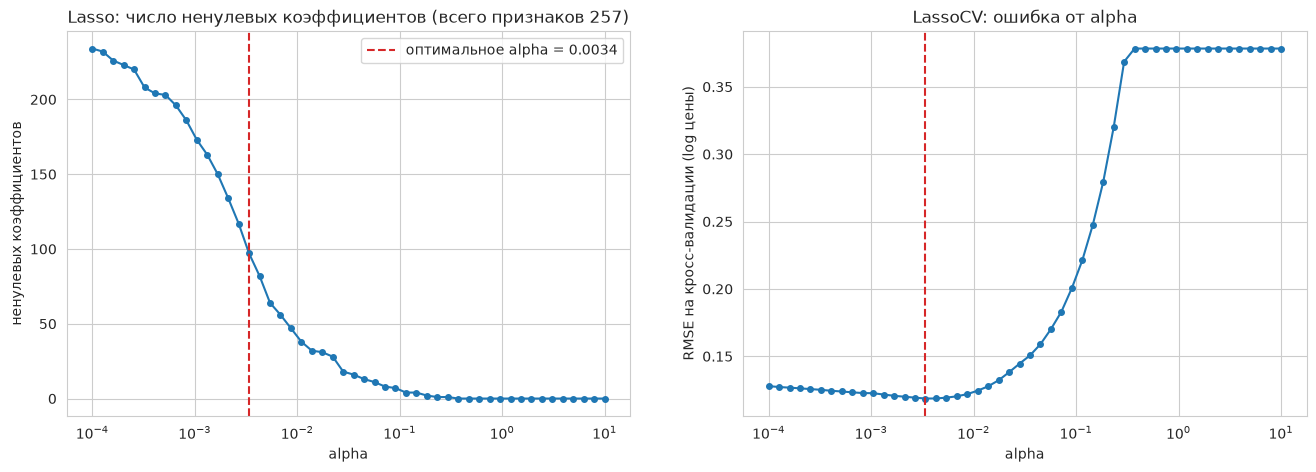

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
ax.plot(path_alphas, nonzero, 'o-', ms=4)
ax.axvline(lasso_cv.alpha_, color='C3', ls='--', label=f'оптимальное alpha = {lasso_cv.alpha_:.4f}')
ax.set(xscale='log', xlabel='alpha', ylabel='ненулевых коэффициентов',
       title=f'Lasso: число ненулевых коэффициентов (всего признаков {Xs.shape[1]})')
ax.legend()

ax = axes[1]
mse_path = lasso_cv.mse_path_.mean(axis=1)
ax.plot(lasso_cv.alphas_, np.sqrt(mse_path), 'o-', ms=4)
ax.axvline(lasso_cv.alpha_, color='C3', ls='--')
ax.set(xscale='log', xlabel='alpha', ylabel='RMSE на кросс-валидации (log цены)', title='LassoCV: ошибка от alpha')
plt.show()

In [21]:
coef = pd.Series(lasso_cv.coef_, index=X_train_ames.columns)
top10 = coef.reindex(coef.abs().sort_values(ascending=False).index[:10])
n_zero = (coef == 0).sum()
print(f'при оптимальном alpha ненулевых: {(coef != 0).sum()} из {len(coef)}; '
      f'исключено {n_zero} признаков, то есть {n_zero / len(coef):.1%}')
num_coef = coef[coef.index.isin(num_cols)]
print(f'исключено среди исходных числовых: {(num_coef == 0).sum()} из {len(num_coef)}:', list(num_coef[num_coef == 0].index))
is_inter = coef.index.str.contains('*', regex=False)
is_ohe = ~coef.index.isin(num_cols) & ~is_inter
print(f'среди One-Hot столбцов: {(coef[is_ohe] == 0).sum()} из {is_ohe.sum()}; '
      f'взаимодействия: { {k: round(float(v), 4) for k, v in coef[is_inter].items()} }')
print('ТОП-10 признаков (коэффициент на 1 std признака, в единицах log цены):')
top10.round(4).to_frame('коэффициент')

при оптимальном alpha ненулевых: 97 из 257; исключено 160 признаков, то есть 62.3%
исключено среди исходных числовых: 14 из 35: ['2ndFlrSF', '3SsnPorch', 'BedroomAbvGr', 'BsmtFinSF2', 'BsmtHalfBath', 'BsmtUnfSF', 'EnclosedPorch', 'LotArea', 'LowQualFinSF', 'MasVnrArea', 'MiscVal', 'OpenPorchSF', 'TotalBsmtSF', 'YrSold']
среди One-Hot столбцов: 145 из 219; взаимодействия: {'LotArea*GrLivArea': 0.0642, 'LotArea*TotalBsmtSF': 0.0, 'GrLivArea*TotalBsmtSF': 0.0135}
ТОП-10 признаков (коэффициент на 1 std признака, в единицах log цены):


,коэффициент
GrLivArea,0.0869
OverallQual,0.0841
LotArea*GrLivArea,0.0642
YearBuilt,0.0547
PoolQC_Gd,-0.0459
OverallCond,0.0411
1stFlrSF,0.0283
BsmtFinSF1,0.0280
GarageCars,0.0241
SaleCondition_Partial,0.0231


**Ответ.**

**Оптимальное alpha = 0.0034.** На test RMSE 0.179 (34 053 $), почти как у ElasticNet: тот выбрал маленькую долю L1, а по качеству они одинаковы.

**Число ненулевых коэффициентов от alpha** (из 257 признаков): при alpha = 1e-4 - 234, 1e-3 - 173, 1e-2 - 38, 0.1 - 7, при alpha >= 1 - ни одного. Чем сильнее штраф, тем больше признаков L1 обнуляет. Ошибка кросс-валидации почти не меняется от 1e-4 до 0.01 (0.12-0.13), минимум при 0.0034, дальше резко растет. Примерно с alpha = 0.4 она равна 0.378, это std цели, то есть модель-константа.

**ТОП-10 признаков** (коэффициент - изменение log-цены на одно стандартное отклонение признака):
1. `GrLivArea` +0.087 - жилая площадь;
2. `OverallQual` +0.084 - общее качество;
3. `LotArea*GrLivArea` +0.064 - созданное взаимодействие сразу попало в топ-3;
4. `YearBuilt` +0.055;
5. `PoolQC_Gd` -0.046 - тот же артефакт одного дома, что и в вопросе 5;
6. `OverallCond` +0.041;
7-10. `1stFlrSF`, `BsmtFinSF1`, `GarageCars`, `SaleCondition_Partial` (новые дома, проданные до завершения строительства).

**Исключено 160 признаков из 257, то есть 62.3%.** Из них 145 из 219 One-Hot столбцов (в основном редкие категории) и 14 из 35 числовых. Среди числовых выкинуты дубли: `2ndFlrSF` уже входит в `GrLivArea`, а `BsmtUnfSF` и `BsmtFinSF2` в сумме с `BsmtFinSF1` дают `TotalBsmtSF`. Сами `LotArea` и `TotalBsmtSF` тоже обнулены: их информацию лучше передают взаимодействия `LotArea*GrLivArea` и `GrLivArea*TotalBsmtSF`. Так Lasso делает отбор признаков: из группы коррелированных признаков оставляет один-два.

## Вопрос 7: Настройка схем скорости обучения (Learning Rate Schedules) в SGDRegressor

Алгоритм стохастического градиентного спуска критически чувствителен к масштабу данных и выбору правила изменения шага $\eta$.

* Отсштабируйте признаки `X_train_ames` и `X_test_ames` с помощью `StandardScaler`.

Обучите четыре версии `SGDRegressor` с регуляризацией `penalty='elasticnet'`, используя различные стратегии `learning_rate`:

1. `'constant'` (`eta0=0.01`)

2. `'optimal'`

3. `'invscaling'` (`eta0=0.01`, `power_t=0.25`)

4. `'adaptive'` (`eta0=0.01`)

* Сравните полученные значения $RMSE$ и общее число итераций до сходимости (`n_iter_`).

In [22]:
from sklearn.exceptions import ConvergenceWarning

scaler = StandardScaler().fit(X_train_ames)
X_train_s = scaler.transform(X_train_ames)
X_test_s = scaler.transform(X_test_ames)


def fit_sgd(**params):
    sgd = SGDRegressor(penalty='elasticnet', max_iter=1000, tol=1e-3, random_state=42, **params)
    t0 = time.time()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        sgd.fit(X_train_s, y_train_ames)
    elapsed = time.time() - t0
    pred_tr, pred_te = sgd.predict(X_train_s), sgd.predict(X_test_s)
    row = {'RMSE train': rmse(y_train_ames, pred_tr), 'RMSE test': rmse(y_test_ames, pred_te),
           'n_iter_': sgd.n_iter_, 'время, с': elapsed,
           'ConvergenceWarning': any(issubclass(w.category, ConvergenceWarning) for w in caught),
           'max |w|': np.abs(sgd.coef_).max()}
    # если модель разошлась, expm1 от огромного прогноза переполняется - доллары не считаю
    row['RMSE test, $'] = rmse(np.expm1(y_test_ames), np.expm1(pred_te)) if row['RMSE test'] < 5 else np.nan
    return sgd, row


fmt_sgd = {'RMSE train': '{:.4g}', 'RMSE test': '{:.4g}', 'RMSE test, $': '{:,.0f}', 'время, с': '{:.2f}',
           'max |w|': '{:.3g}'}
schedules = {
    'constant (eta0=0.01)': dict(learning_rate='constant', eta0=0.01),
    'optimal': dict(learning_rate='optimal'),
    'invscaling (eta0=0.01, power_t=0.25)': dict(learning_rate='invscaling', eta0=0.01, power_t=0.25),
    'adaptive (eta0=0.01)': dict(learning_rate='adaptive', eta0=0.01),
}
sgd_df = pd.DataFrame({name: fit_sgd(**params)[1] for name, params in schedules.items()}).T
fmt_table(sgd_df, fmt_sgd)

,RMSE train,RMSE test,n_iter_,"время, с",ConvergenceWarning,max |w|,"RMSE test, $"
constant (eta0=0.01),1.731e+12,2.015e+12,6,0.01,False,3.65e+11,-
optimal,2.749e+13,2.997e+13,80,0.08,False,5.92e+12,-
"invscaling (eta0=0.01, power_t=0.25)",52.91,20.82,6,0.01,False,22.1,-
adaptive (eta0=0.01),5.658e+10,1.833e+11,36,0.03,False,7.9e+10,-


||x||^2 после StandardScaler: среднее 257 (= числу признаков), медиана 177, максимум 2254
порог шага 2 / ||x||^2: для среднего объекта 0.0078, для самого "длинного" 0.00089
самые большие стандартизованные значения (редкие категории): {'PoolQC_Gd': 31.0, 'RoofMatl_Roll': 31.0, 'Exterior1st_BrkComm': 31.0, 'MiscFeature_Othr': 31.0}
optimal при alpha = 0.0001: начальный шаг 10.0, ниже порога только после 1331 эпох (max_iter = 1000)


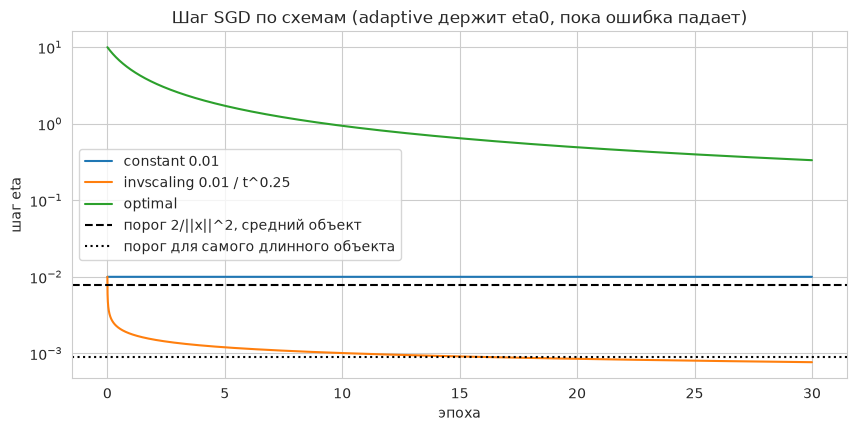

In [23]:
# почему расходится: для квадратичной потери шаг SGD по одному объекту устойчив, только если eta * ||x||^2 < 2
sq_norm = (X_train_s ** 2).sum(axis=1)
print(f'||x||^2 после StandardScaler: среднее {sq_norm.mean():.0f} (= числу признаков), '
      f'медиана {np.median(sq_norm):.0f}, максимум {sq_norm.max():.0f}')
print(f'порог шага 2 / ||x||^2: для среднего объекта {2 / sq_norm.mean():.4f}, для самого "длинного" {2 / sq_norm.max():.5f}')
rare = pd.Series(np.abs(X_train_s).max(axis=0), index=X_train_ames.columns).sort_values(ascending=False)
print('самые большие стандартизованные значения (редкие категории):', rare.head(4).round(1).to_dict())

# схема optimal (формула из исходников sklearn, _sgd_fast.pyx.tp): eta = 1 / (alpha * (t0 + t - 1)),
# t0 = 1 / (alpha * eta_start), eta_start = alpha ** -0.25 для квадратичной потери
alpha_def = SGDRegressor().alpha
eta_start = alpha_def ** -0.25
t0_opt = 1 / (alpha_def * eta_start)
t_stable = 1 / (alpha_def * 2 / sq_norm.mean()) - t0_opt + 1
print(f'optimal при alpha = {alpha_def}: начальный шаг {eta_start:.1f}, '
      f'ниже порога только после {t_stable / len(X_train_s):.0f} эпох (max_iter = 1000)')

n = len(X_train_s)
t = np.arange(1, 30 * n)
etas = {'constant 0.01': np.full(t.shape, 0.01), 'invscaling 0.01 / t^0.25': 0.01 / t ** 0.25,
        'optimal': 1 / (alpha_def * (t0_opt + t - 1))}
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, eta in etas.items():
    ax.plot(t / n, eta, label=name)
ax.axhline(2 / sq_norm.mean(), color='k', ls='--', label='порог 2/||x||^2, средний объект')
ax.axhline(2 / sq_norm.max(), color='k', ls=':', label='порог для самого длинного объекта')
ax.set(yscale='log', xlabel='эпоха', ylabel='шаг eta',
       title='Шаг SGD по схемам (adaptive держит eta0, пока ошибка падает)')
ax.legend(fontsize=10)
plt.show()

In [24]:
# те же схемы, но с шагом ниже порога устойчивости
schedules_small = {
    'constant (eta0=0.0003)': dict(learning_rate='constant', eta0=3e-4),
    'invscaling (eta0=0.0003, power_t=0.25)': dict(learning_rate='invscaling', eta0=3e-4, power_t=0.25),
    'invscaling (eta0=0.001, power_t=0.25)': dict(learning_rate='invscaling', eta0=1e-3, power_t=0.25),
    'adaptive (eta0=0.0003)': dict(learning_rate='adaptive', eta0=3e-4),
    'adaptive (eta0=0.001)': dict(learning_rate='adaptive', eta0=1e-3),
    'optimal, alpha=0.01': dict(learning_rate='optimal', alpha=0.01),
}
sgd_df2 = pd.DataFrame({name: fit_sgd(**params)[1] for name, params in schedules_small.items()}).T
sgd_df2.loc['ElasticNet из вопроса 5 (координатный спуск)'] = {
    'RMSE train': rmse(y_train_ames, best_enet.predict(X_train_ames)),
    'RMSE test': rmse(y_test_ames, best_enet.predict(X_test_ames)),
    'RMSE test, $': rmse(np.expm1(y_test_ames), np.expm1(best_enet.predict(X_test_ames))),
    'n_iter_': best_enet[-1].n_iter_, 'время, с': np.nan, 'ConvergenceWarning': False,
    'max |w|': np.abs(best_enet[-1].coef_).max()}
fmt_table(sgd_df2, fmt_sgd)

,RMSE train,RMSE test,n_iter_,"время, с",ConvergenceWarning,max |w|,"RMSE test, $"
constant (eta0=0.0003),0.08046,0.1865,24,0.02,False,0.0585,"32,767"
"invscaling (eta0=0.0003, power_t=0.25)",0.2645,0.3085,213,0.18,False,0.0579,"52,845"
"invscaling (eta0=0.001, power_t=0.25)",0.1177,0.206,59,0.05,False,0.0618,"36,301"
adaptive (eta0=0.0003),0.07985,0.1868,44,0.04,False,0.0589,"32,758"
adaptive (eta0=0.001),0.08193,0.2014,42,0.04,False,0.0611,"35,530"
"optimal, alpha=0.01",5.009e+10,3.979e+10,94,0.09,False,2.21e+10,-
ElasticNet из вопроса 5 (координатный спуск),0.08882,0.179,222,-,False,0.0824,"33,898"


**Ответ.**

**С заданными параметрами все четыре схемы не работают.** `constant`, `optimal` и `adaptive` разошлись: RMSE 10^10-10^13, веса до 6·10^12. `invscaling` не улетел в бесконечность, но RMSE test 20.8 в log-шкале - это бесполезная модель. При этом `n_iter_` маленький (6-80), и **ConvergenceWarning нет**. sklearn останавливает SGD, когда ошибка 5 эпох подряд не улучшилась на `tol`, а при расходимости она как раз не улучшается. Значит, маленький `n_iter_` не означает, что модель сошлась, ошибку нужно проверять отдельно.

**Почему.** Для квадратичной потери шаг SGD по одному объекту устойчив, только если eta·||x||^2 < 2. После `StandardScaler` у каждого признака дисперсия 1, поэтому ||x||^2 в среднем равно числу признаков, 257, и порог равен 0.0078. У самого «длинного» объекта ||x||^2 = 2254: редкие категории после стандартизации дают значения до 31, а 31^2 = 961. Для него порог 0.00089. Шаг 0.01 выше обоих порогов.
- `optimal` начинает с шага alpha^(-1/4) = 10 (формула из исходников sklearn) и опустился бы ниже порога только примерно через 1300 эпох. Эта схема рассчитана на классификационные потери с ограниченным градиентом, а не на квадратичную.
- `invscaling` (0.01/t^0.25) опускается ниже среднего порога уже после 3 обновлений, но ниже порога для «длинных» объектов только примерно через 16 тысяч обновлений, около 16 эпох (на графике место, где оранжевая линия пересекает пунктир). За это время каждый объект с редкой категорией отбрасывает веса, а SGD останавливается уже на 6-й эпохе, потому что ошибка не улучшается.
- `adaptive` делит шаг на 5, когда ошибка перестает падать, но веса уже разлетелись в первую эпоху.

**С шагом ниже порога** (`eta0 = 0.0003`):

| схема | RMSE test (log) | RMSE test, $ | n_iter_ |
|---|---|---|---|
| constant | 0.1865 | 32 767 | 24 |
| adaptive | 0.1868 | 32 758 | 44 |
| invscaling | 0.3085 | 52 845 | 213 |
| ElasticNet, координатный спуск (вопрос 5) | 0.179 | 33 898 | 222 |

`constant` и `adaptive` сходятся быстро и в долларах не хуже точного решателя. `invscaling` с маленьким `eta0` затухает слишком рано и недообучается (RMSE train 0.26), с `eta0 = 0.001` ему уже лучше (0.206 за 59 эпох). `optimal` расходится даже с `alpha = 0.01`: стартовый шаг 0.01^(-1/4), около 3.2, все равно слишком большой.

Вывод: SGD нужно масштабирование, `eta0` ниже 2/||x||^2, и проверка реальной ошибки, а не числа итераций. Самая «прощающая» схема - `adaptive`.

## Вопрос 8: Сравнительный анализ устойчивости моделей к выбросам (Outliers)

Среднеквадратичная ошибка ($MSE$) в оптимизации градиентным спуском квадратично штрафует отклонения, делая модели чувствительными к аномалиям.

* Добавьте в 5% случайных точек обучающей выборки `y_train_ames` аномальные выбросы (увеличьте их значение в 3 раза).

* Обучите следующие модели на искаженных данных:

1. OLS (`LinearRegression`)
2. Ridge (`RidgeCV`)     
3. SGDRegressor с функциями потерь `loss='squared_error'` ($L_2$) и `loss='huber'` (Huber loss, комбинирующий $L_1$ и $L_2$).

* Оцените $RMSE$ и $MAE$ каждой модели на чистой тестовой выборке `y_test_ames`.

Сделайте выводы об устойчивости функции потерь Хьюбера по сравнению с классической регрессией.

     

In [25]:
rng_out = np.random.default_rng(0)
n_out = int(round(0.05 * len(y_train_ames)))
out_idx = rng_out.choice(len(y_train_ames), size=n_out, replace=False)

# выброс: цена дома завышена в 3 раза (цель у нас log1p цены, поэтому пересчитываю через доллары)
y_train_out = y_train_ames.copy()
y_train_out.iloc[out_idx] = np.log1p(3 * np.expm1(y_train_ames.iloc[out_idx]))
print(f'выбросов: {n_out} из {len(y_train_ames)}; в log-шкале каждый сдвинут на ~{np.log(3):.2f} '
      f'(std цели {y_train_ames.std():.2f})')


def outlier_models():
    return {
        'OLS (LinearRegression)': LinearRegression(),
        'Ridge (RidgeCV)': RidgeCV(alphas=np.logspace(-2, 4, 25)),
        # шаг 0.0003 - устойчивый из вопроса 7
        'SGD, squared_error': SGDRegressor(loss='squared_error', penalty='l2', learning_rate='adaptive',
                                           eta0=3e-4, max_iter=2000, random_state=42),
        'SGD, huber': SGDRegressor(loss='huber', epsilon=0.1, penalty='l2', learning_rate='adaptive',
                                   eta0=3e-4, max_iter=2000, random_state=42),
    }


rows = {}
for label, y_fit in [('чистые', y_train_ames), ('с выбросами', y_train_out)]:
    for name, model in outlier_models().items():
        model.fit(X_train_s, y_fit)
        pred = model.predict(X_test_s)
        rows[(name, label)] = {'RMSE (log)': rmse(y_test_ames, pred),
                               'MAE (log)': mean_absolute_error(y_test_ames, pred),
                               'RMSE, $': rmse(np.expm1(y_test_ames), np.expm1(pred)),
                               'MAE, $': mean_absolute_error(np.expm1(y_test_ames), np.expm1(pred)),
                               'средний сдвиг прогноза, %': 100 * np.mean(np.expm1(pred) / np.expm1(y_test_ames) - 1),
                               'alpha': getattr(model, 'alpha_', np.nan)}
out_df = pd.DataFrame(rows).T
fmt_table(out_df, {'RMSE (log)': '{:.4f}', 'MAE (log)': '{:.4f}', 'RMSE, $': '{:,.0f}', 'MAE, $': '{:,.0f}',
                     'средний сдвиг прогноза, %': '{:+.1f}', 'alpha': '{:.3g}'})

выбросов: 48 из 965; в log-шкале каждый сдвинут на ~1.10 (std цели 0.38)


,,RMSE (log),MAE (log),"RMSE, $","MAE, $","средний сдвиг прогноза, %",alpha
OLS (LinearRegression),чистые,0.1687,0.1016,"34,901","18,523",+1.8,-
Ridge (RidgeCV),чистые,0.1766,0.0977,"32,347","17,204",+1.5,100
"SGD, squared_error",чистые,0.1868,0.1021,"32,758","17,782",+1.1,-
"SGD, huber",чистые,0.1721,0.1006,"33,527","18,042",-0.6,-
OLS (LinearRegression),с выбросами,0.2910,0.1832,"86,535","38,683",+13.5,-
Ridge (RidgeCV),с выбросами,0.1880,0.1216,"39,979","22,954",+9.0,562
"SGD, squared_error",с выбросами,0.2475,0.1557,"59,950","30,967",+10.3,-
"SGD, huber",с выбросами,0.1711,0.1000,"33,668","18,020",-0.0,-


In [26]:
# во сколько раз выбросы ухудшили каждую модель
deg = (out_df.xs('с выбросами', level=1)[['RMSE, $', 'MAE, $']]
       / out_df.xs('чистые', level=1)[['RMSE, $', 'MAE, $']])
deg.columns = ['рост RMSE, раз', 'рост MAE, раз']
deg.round(2)

,"рост RMSE, раз","рост MAE, раз"
OLS (LinearRegression),2.48,2.09
Ridge (RidgeCV),1.24,1.33
"SGD, squared_error",1.83,1.74
"SGD, huber",1.00,1.00


**Ответ.**

Выбросы: у 48 из 965 домов train (5%) цена увеличена в 3 раза. Цель у нас в log-шкале, поэтому каждый такой дом сдвинут на ln 3, около 1.10, это примерно 2.9 std цели. Все модели на стандартизованных признаках, у SGD устойчивый шаг 0.0003 из вопроса 7, test чистый.

| модель | RMSE, $ (чистые -> с выбросами) | рост RMSE | рост MAE | средний сдвиг прогноза |
|---|---|---|---|---|
| OLS | 34 901 -> 86 535 | x2.48 | x2.09 | +13.5% |
| RidgeCV | 32 347 -> 39 979 | x1.24 | x1.33 | +9.0% |
| SGD, squared_error | 32 758 -> 59 950 | x1.83 | x1.74 | +10.3% |
| SGD, huber | 33 527 -> 33 668 | **x1.00** | **x1.00** | 0.0% |

- **Квадратичная потеря** (OLS, Ridge, SGD squared) тянет модель к выбросам: квадрат ошибки 1.1 весит примерно в 120 раз больше, чем квадрат обычной ошибки около 0.1. Вся модель сдвигается вверх (прогнозы в среднем завышены на 9-14%), и OLS еще подгоняет коэффициенты редких признаков под конкретные выбросы, отсюда рост RMSE в 2.5 раза.
- **Ridge** страдает меньше: RidgeCV сам усилил регуляризацию (alpha 100 -> 562), и коэффициентам труднее подстроиться под отдельные дома. Но общий сдвиг вверх остается, лечить сам выброс регуляризация не умеет.
- **Huber** (`epsilon = 0.1`, в log-шкале это около 10% цены) для ошибок больше epsilon штрафует линейно, а не квадратично. Градиент от одного выброса ограничен, и 48 выбросов не могут перетянуть модель: ошибка на test та же, что без выбросов, сдвига нет. На чистых данных Huber не хуже квадратичной потери (0.172 против 0.187 в log-шкале).

Вывод: MSE чувствительна к выбросам, потеря Хьюбера устойчива и при этом гладкая около нуля, в отличие от MAE. `epsilon` задает границу: слишком маленький делает Huber похожим на MAE (медианная регрессия), слишком большой - на обычную MSE.